# TS7: Filtrado digital lineal de ECG
## Alumno: Matías Carbajal
## Materia: Análisis y Procesamiento de Señales (APS)
## Carrera: Ingeniería Telecomunicaciones
## Fecha: 4 de noviembre de 2026

# 1. Introducción Teórica:

(filtros fir e iir).

# 2. Análisis y Desarrollo.

## 2.1 Filtros IIR.

In [13]:
#IMPORTACIONES 
import numpy as np
import scipy.io as sio
import scipy.signal as signal              
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

In [14]:
#%% ============================================================
# 1. LECTURA DE LA SEÑAL ECG
# ============================================================

fs_ecg = 1000.0  # Frecuencia de muestreo [Hz]

# Cargar archivo .mat
mat_struct = sio.loadmat('./ECG_TP4.mat')

# Extraer señal ECG
ecg_one_lead = mat_struct['ecg_lead'].flatten().astype(float)

# Patrones de latidos
hb_1 = mat_struct['heartbeat_pattern1']
hb_2 = mat_struct['heartbeat_pattern2']

# Cantidad de muestras y vector temporal
N = len(ecg_one_lead)
t_ecg = np.arange(N) / fs_ecg
# ============================================================


In [15]:
#%%................... Diseño de filtro ...................

wp = 35       # [Hz] Frecuencia límite de banda pasante
ws = 50       # [Hz] Frecuencia límite de banda de rechazo
Gpass = 3     # [dB] Atenuación máxima en banda pasante
Gstop = 40    # [dB] Atenuación mínima en banda de rechazo

ripple = Gpass
att = Gstop

# Diseño de los tres filtros
sos_butt = signal.iirdesign(
    wp, ws, Gpass, Gstop,
    ftype='butter', fs=fs_ecg, output='sos'
)

sos_cheby2 = signal.iirdesign(
    wp, ws, Gpass, Gstop,
    ftype='cheby2', fs=fs_ecg, output='sos'
)

sos_cauer = signal.iirdesign(
    wp, ws, Gpass, Gstop,
    ftype='cauer', fs=fs_ecg, output='sos'
)

y_min, y_max = -100, 5
# ============================================================

Explicar xq se eligio estos valores para el diseño de filtro

In [16]:
#%% Función para calcular y graficar las respuestas

def calc_resp(sos, leg_str, fig_n_axes):

    # Respuesta en frecuencia
    f, h = signal.freqz_sos(sos, worN=8192, fs=fs_ecg)

    # Módulo en dB
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))

    # Fase
    fase_rad = np.unwrap(np.angle(h))

    # Retardo de grupo
    omega = 2 * np.pi * f
    retardo_s = -np.gradient(fase_rad, omega)

    # Evitar graficar retardos donde el filtro rechaza
    # prácticamente toda la señal
    umbral_db = -80
    valido = modulo_db > umbral_db
    retardo_s_plot = np.where(valido, retardo_s, np.nan)

    (fig, (ax_mod, ax_fase)) = fig_n_axes

    # Módulo
    ax_mod.plot(f, modulo_db, linewidth=1.5, label=leg_str)
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en frecuencia y plantilla")
    ax_mod.grid(True)

    # Fase
    ax_fase.plot(f, fase_rad, label=leg_str, linewidth=1.2)
    ax_fase.axvline(wp, color="gray", linestyle=":")
    ax_fase.axvline(ws, color="gray", linestyle=":")
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_fase.grid(True)

    # Retardo de grupo
    plt.figure(2, figsize=(10, 4))
    plt.plot(f, retardo_s_plot, label=leg_str)
    plt.axvline(wp, color="orange", linestyle="--",
                label=f"wp = {wp} Hz")
    plt.axvline(ws, color="red", linestyle="--",
                label=f"ws = {ws} Hz")
    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("Retardo de grupo (s)")
    plt.title("Retardo de grupo del filtro IIR")
    plt.grid(True)
    plt.legend()
# ============================================================

C:\Users\DELL\AppData\Local\Temp\ipykernel_16376\4002055180.py:42: UserWarning: Ignoring specified arguments in this call because figure with num: 2 already exists
  plt.figure(2, figsize=(10, 4))


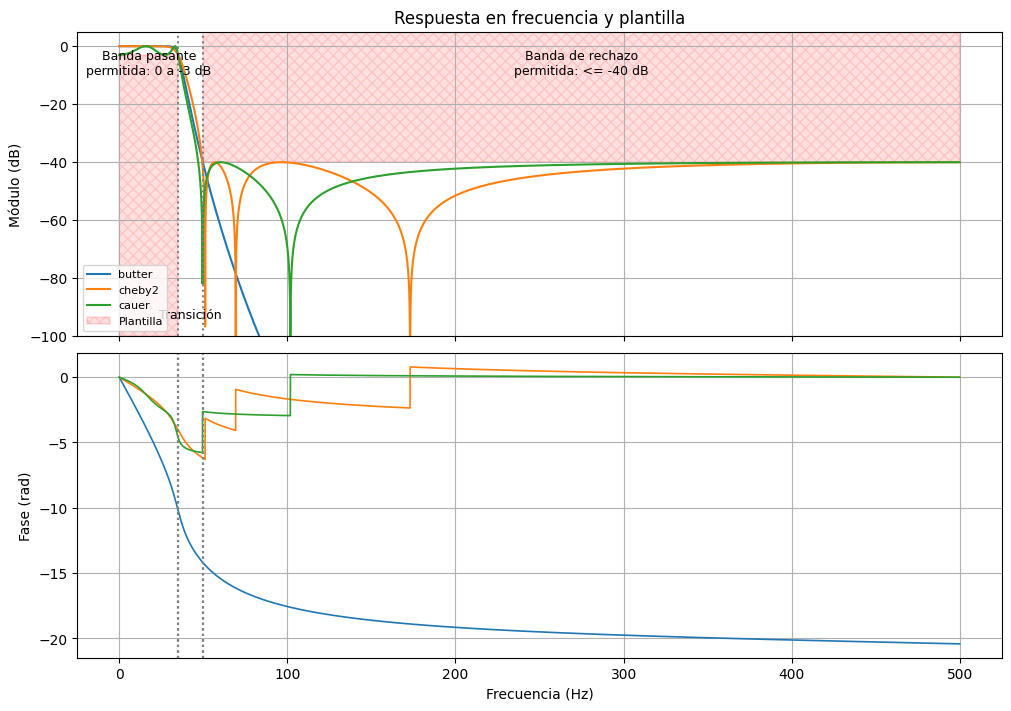

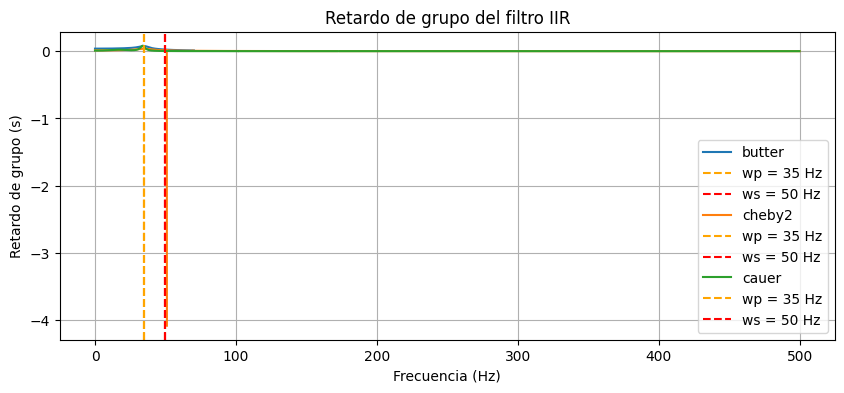

In [17]:
#%% Graficar las respuestas de los filtros

plt.close('all')

fig_n_axes = plt.subplots(
    2, 1, sharex=True, num=1,
    figsize=(10, 7), constrained_layout=True
)

calc_resp(sos_butt, 'butter', fig_n_axes)
calc_resp(sos_cheby2, 'cheby2', fig_n_axes)
calc_resp(sos_cauer, 'cauer', fig_n_axes)


#%% Graficar la plantilla del filtro

(fig, (ax_mod, ax_fase)) = fig_n_axes

# Banda pasante
rect_pasante = Rectangle(
    (0, y_min), wp, -ripple - y_min,
    facecolor="red", alpha=0.12,
    edgecolor="red", hatch="xxx",
    linewidth=1.2, label='Plantilla'
)

ax_mod.add_patch(rect_pasante)

# Banda de rechazo
rect_rechazo = Rectangle(
    (ws, -att), fs_ecg / 2 - ws, y_max + att,
    facecolor="red", alpha=0.12,
    edgecolor="red", hatch="xxx",
    linewidth=1.2
)

ax_mod.add_patch(rect_rechazo)

# Límites de frecuencia
ax_mod.axvline(wp, color="gray", linestyle=":")
ax_mod.axvline(ws, color="gray", linestyle=":")

# Etiquetas
ax_mod.text(
    wp / 2, y_max - 6,
    "Banda pasante\npermitida: 0 a -3 dB",
    ha="center", va="top", fontsize=9
)

ax_mod.text(
    (ws + fs_ecg / 2) / 2, y_max - 6,
    "Banda de rechazo\npermitida: <= -40 dB",
    ha="center", va="top", fontsize=9
)

ax_mod.text(
    (wp + ws) / 2, y_min + 5,
    "Transición",
    ha="center", va="bottom", fontsize=9
)

ax_mod.legend(loc="lower left", fontsize=8)


A partir de las gráficas de respuesta en frecuencia, módulo y fase, se observan los siguientes comportamientos para cada aproximación:

* **Filtro Cauer (Elíptico):**
  * **Módulo:** Presenta rizado (*equiripple*) tanto en la banda de paso como en la de rechazo. Es el filtro con la **transición más abrupta** (mayor pendiente de caída), logrando cumplir holgadamente con la plantilla exigida ($G_{pass} \ge -3\text{ dB}$ en $wp = 35\text{ Hz}$ y $G_{stop} \le -40\text{ dB}$ en $ws = 50\text{ Hz}$).
  * **Ceros de transmisión:** Ubica sus ceros finitos muy cerca del borde de la banda de transición, lo que acelera la caída de la ganancia.
  * **Fase:** Muestra la mayor distorsión de fase no lineal, observándose saltos/discontinuidades de $\pi\text{ rad}$ exactamente en las frecuencias donde se encuentran los ceros de transmisión.

* **Filtro Chebyshev Tipo II (Inverso):**
  * **Módulo:** Presenta comportamiento **monótono (sin rizado) en la banda de paso**, mientras que en la banda de rechazo muestra rizado y ceros de transmisión finitos.
  * **Comparación con Cauer:** Para un mismo orden de filtro, posee la misma cantidad de ceros finitos que Cauer, pero distribuidos a frecuencias más alejadas de la zona de transición, lo que resulta en una caída menos abrupta.

* **Filtro Butterworth:**
  * **Módulo:** Presenta **máxima planicidad** (respuesta monótona en ambas bandas, sin rizado ni ceros de transmisión finitos). Atenúa de forma suave y progresiva dentro de la banda pasante hasta alcanzar exactamente $-3\text{ dB}$ en $wp = 35\text{ Hz}$.
  * **Fase:** Es el filtro que presenta la curva de fase más suave y continua, minimizando la distorsión de fase al no poseer ceros en el plano.

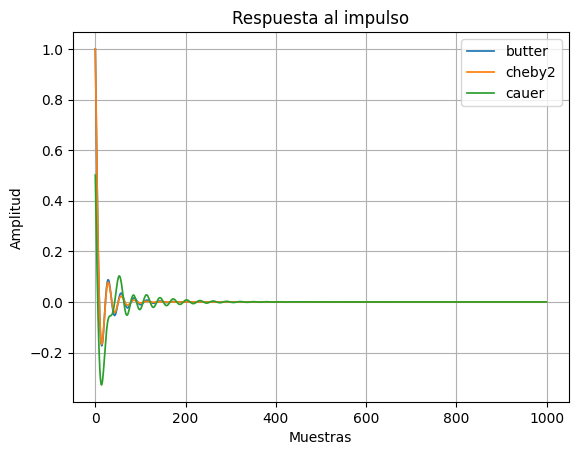

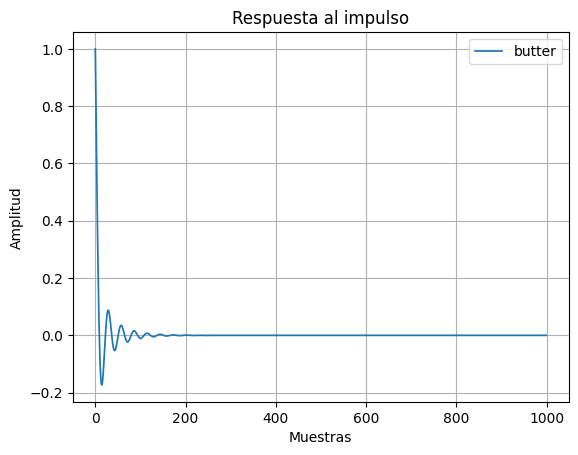

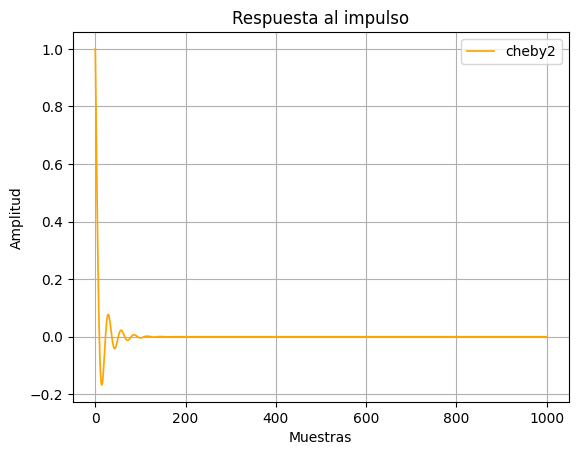

In [18]:
#%% Calcular la respuesta al impulso

delta_k = signal.unit_impulse(1000)

resp_imp_butt = signal.sosfiltfilt(sos_butt, delta_k)
resp_imp_cheby2 = signal.sosfiltfilt(sos_cheby2, delta_k)
resp_imp_cauer = signal.sosfiltfilt(sos_cauer, delta_k)


#%% Graficar respuesta al impulso

plt.figure(3)

plt.plot(resp_imp_butt, linewidth=1.25, label='butter')
plt.plot(resp_imp_cheby2, linewidth=1.25, label='cheby2')
plt.plot(resp_imp_cauer, linewidth=1.25, label='cauer')
plt.legend()
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.title("Respuesta al impulso")
plt.grid(True)
plt.figure(4)
plt.plot(resp_imp_butt, linewidth=1.25, label='butter')
plt.legend()
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.title("Respuesta al impulso")
plt.grid(True)
plt.figure(5)
plt.plot(resp_imp_cheby2, linewidth=1.25, label='cheby2',color= 'orange')

plt.legend()
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.title("Respuesta al impulso")
plt.grid(True)

plt.show()

En la respuesta al impulso se puede observar claramente que el filtro de cauer es el que mas perdura en el tiempo mientras que el de butter y chevy son los que menos perdura.

In [19]:
#%% Filtrado de la señal ECG

ECG_f_butt = signal.sosfilt(sos_butt, ecg_one_lead)
ECG_f_cheby2 = signal.sosfilt(sos_cheby2, ecg_one_lead)
ECG_f_cauer = signal.sosfilt(sos_cauer, ecg_one_lead)


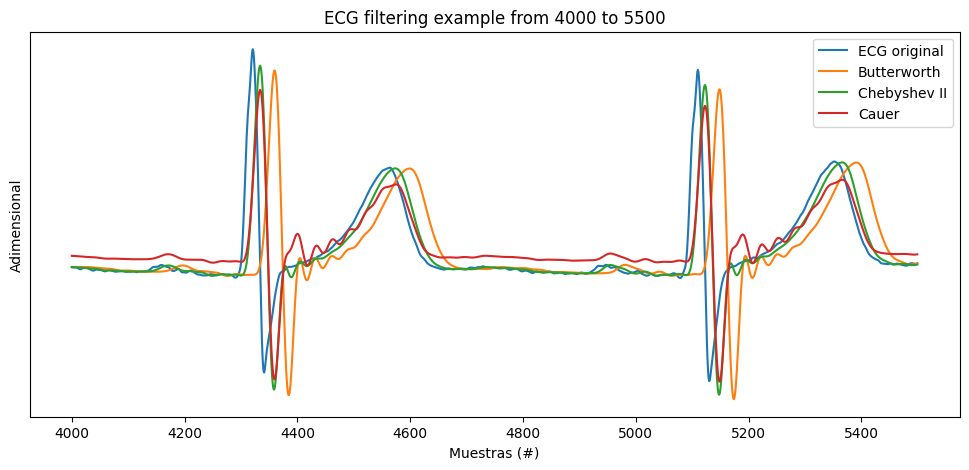

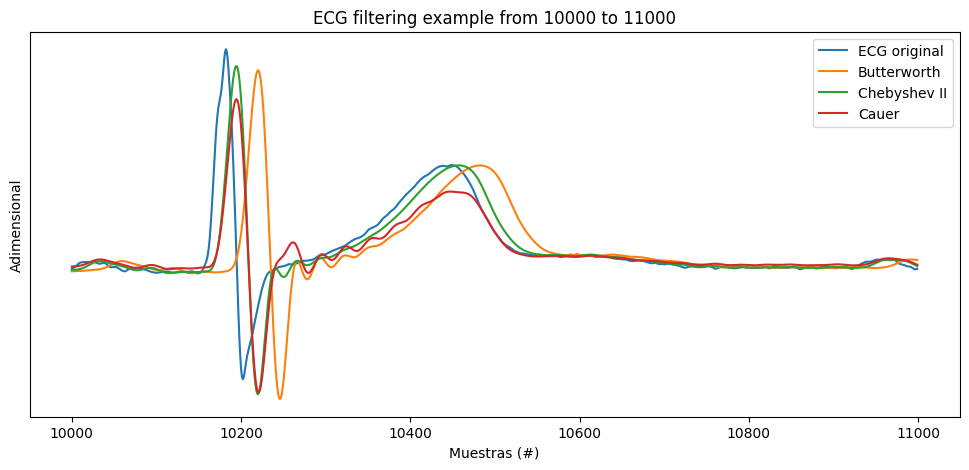

In [20]:
#%% Regiones de interés con ruido

cant_muestras = ecg_one_lead.shape[0]

regs_interes = (
    [4000, 5500],       # muestras
    [10e3, 11e3],       # muestras
)

for ii in regs_interes:

    # Intervalo limitado de 0 a cant_muestras
    inicio = int(max(0, ii[0]))
    fin = int(min(cant_muestras, ii[1]))

    zoom_region = np.arange(inicio, fin)

    plt.figure(figsize=(12, 5))

    plt.plot(zoom_region, ecg_one_lead[inicio:fin],
             label='ECG original', linewidth=1.5)

    plt.plot(zoom_region, ECG_f_butt[inicio:fin],
             label='Butterworth')

    plt.plot(zoom_region, ECG_f_cheby2[inicio:fin],
             label='Chebyshev II')

    plt.plot(zoom_region, ECG_f_cauer[inicio:fin],
             label='Cauer')

    plt.title('ECG filtering example from ' +
              str(inicio) + ' to ' + str(fin))

    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')

    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())

    plt.show()

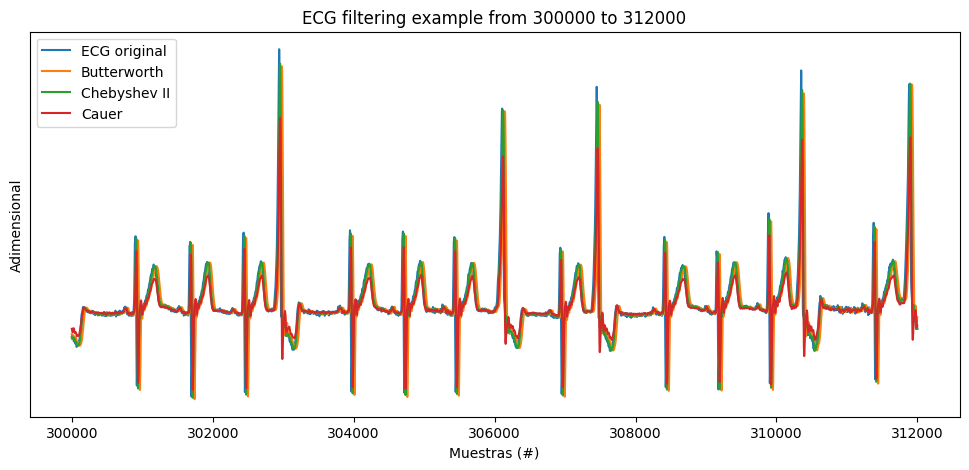

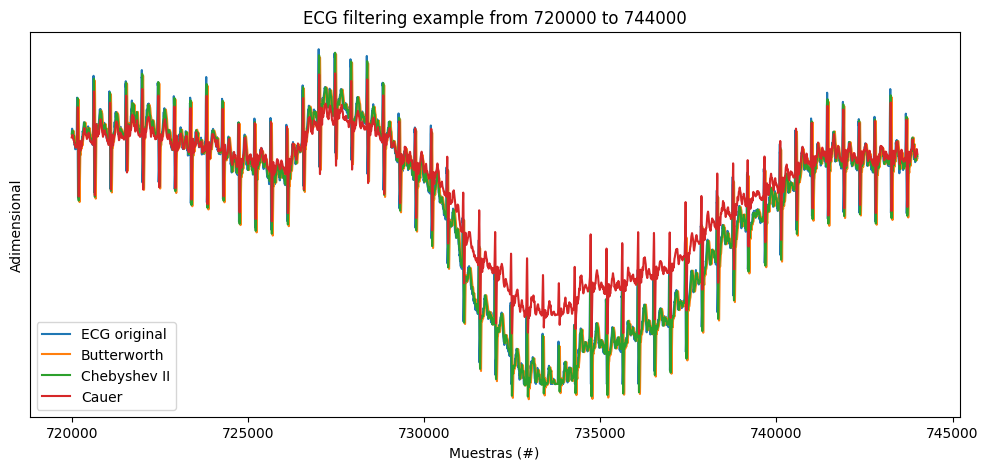

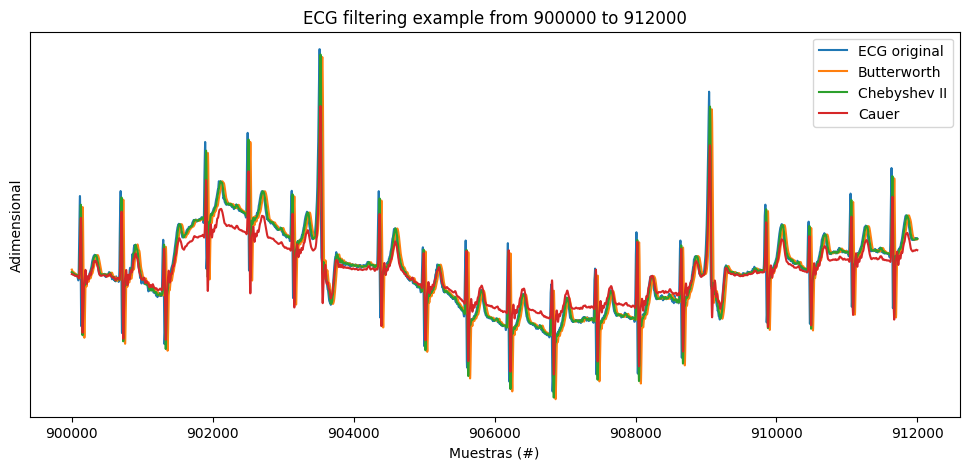

In [21]:
#%% Regiones de interés sin ruido

regs_interes = (
    np.array([5, 5.2]) * 60 * fs_ecg,   # minutos a muestras
    np.array([12, 12.4]) * 60 * fs_ecg,
    np.array([15, 15.2]) * 60 * fs_ecg,
)

for ii in regs_interes:

    # Intervalo limitado de 0 a cant_muestras
    inicio = int(max(0, ii[0]))
    fin = int(min(cant_muestras, ii[1]))

    zoom_region = np.arange(inicio, fin)

    plt.figure(figsize=(12, 5))

    plt.plot(zoom_region, ecg_one_lead[inicio:fin],
             label='ECG original', linewidth=1.5)

    plt.plot(zoom_region, ECG_f_butt[inicio:fin],
             label='Butterworth')

    plt.plot(zoom_region, ECG_f_cheby2[inicio:fin],
             label='Chebyshev II')

    plt.plot(zoom_region, ECG_f_cauer[inicio:fin],
             label='Cauer')

    plt.title('ECG filtering example from ' +
              str(inicio) + ' to ' + str(fin))

    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')

    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())

    plt.show()

A partir de la comparación en el dominio del tiempo con filtrado causal (`lfilter`), se observa un claro **desfase temporal y distorsión ** entre la señal original y las salidas de los tres filtros IIR.

Dado que la señal de ECG ya se encuentra adquirida (procesamiento *offline*), es posible aplicar la técnica de **filtrado bidireccional de fase cero** mediante `scipy.signal.filtfilt`.
Al aplicar dos veces el filtro estaremos atenuando dos veces la señal por lo tanto tenemos que hacer una predistorsion de la plantilla.

In [28]:
Gpass_predist = Gpass / 2.0  # 1.5 dB
Gstop_predist = Gstop / 2.0  # 20.0 dB

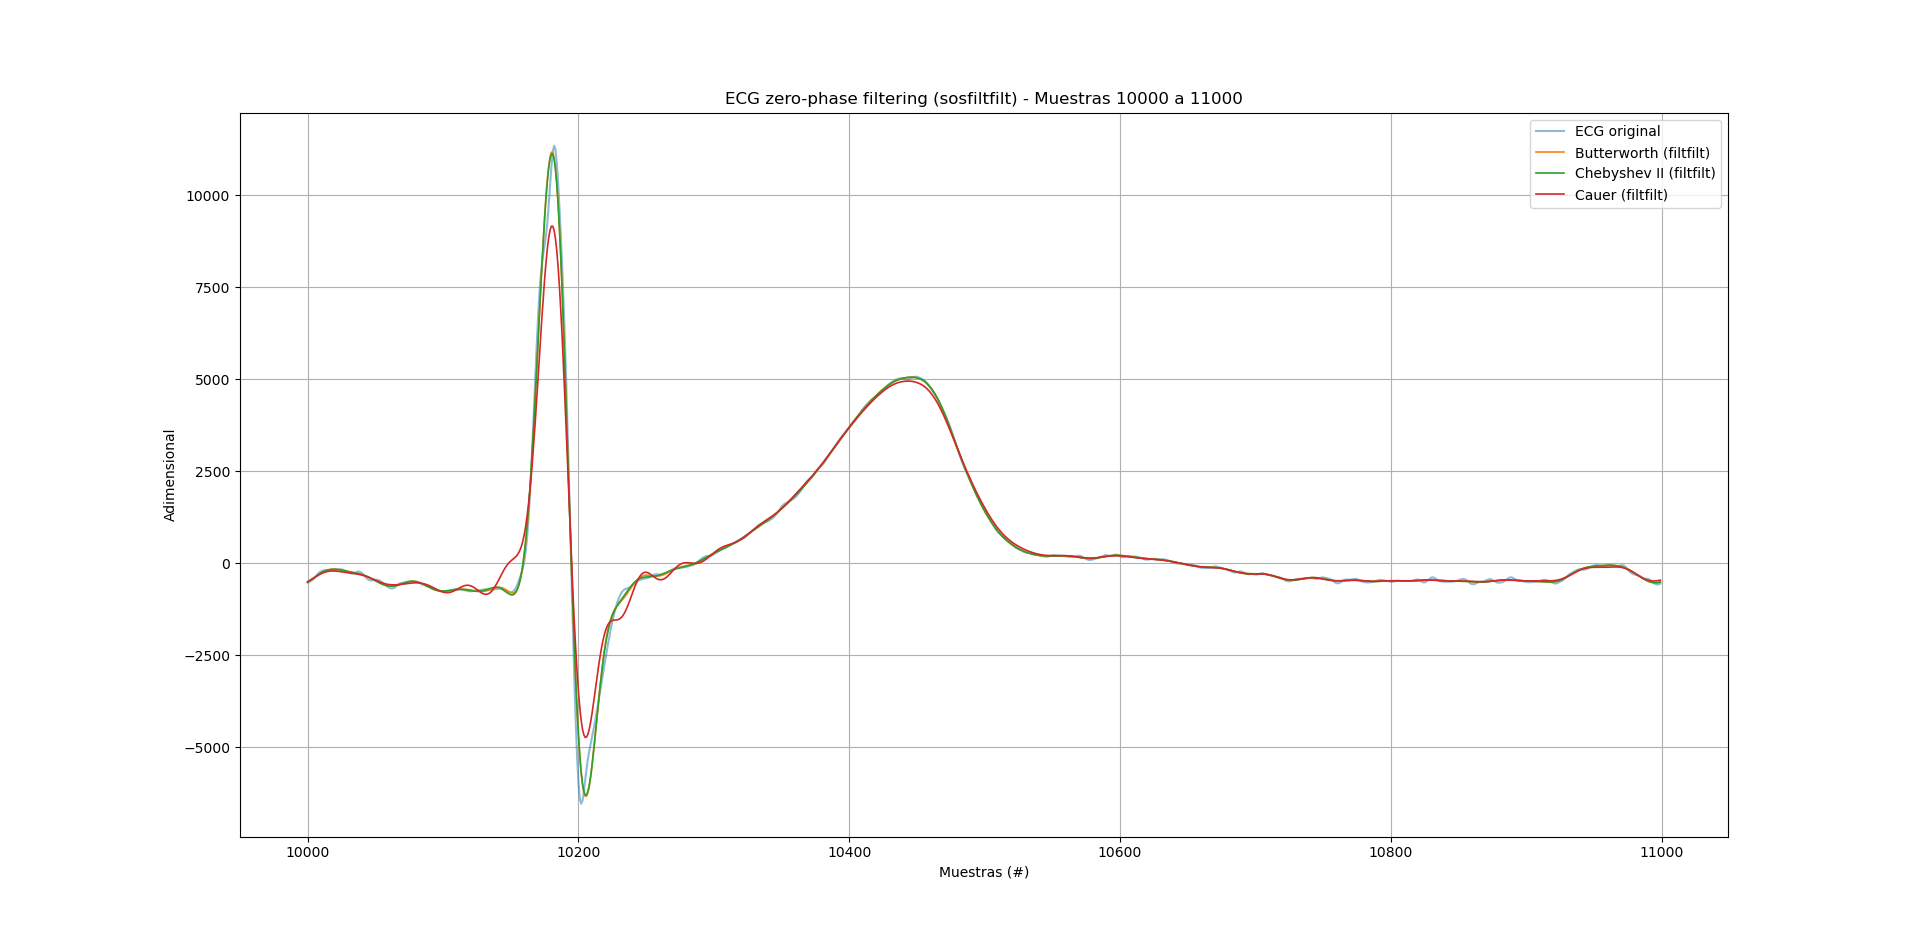

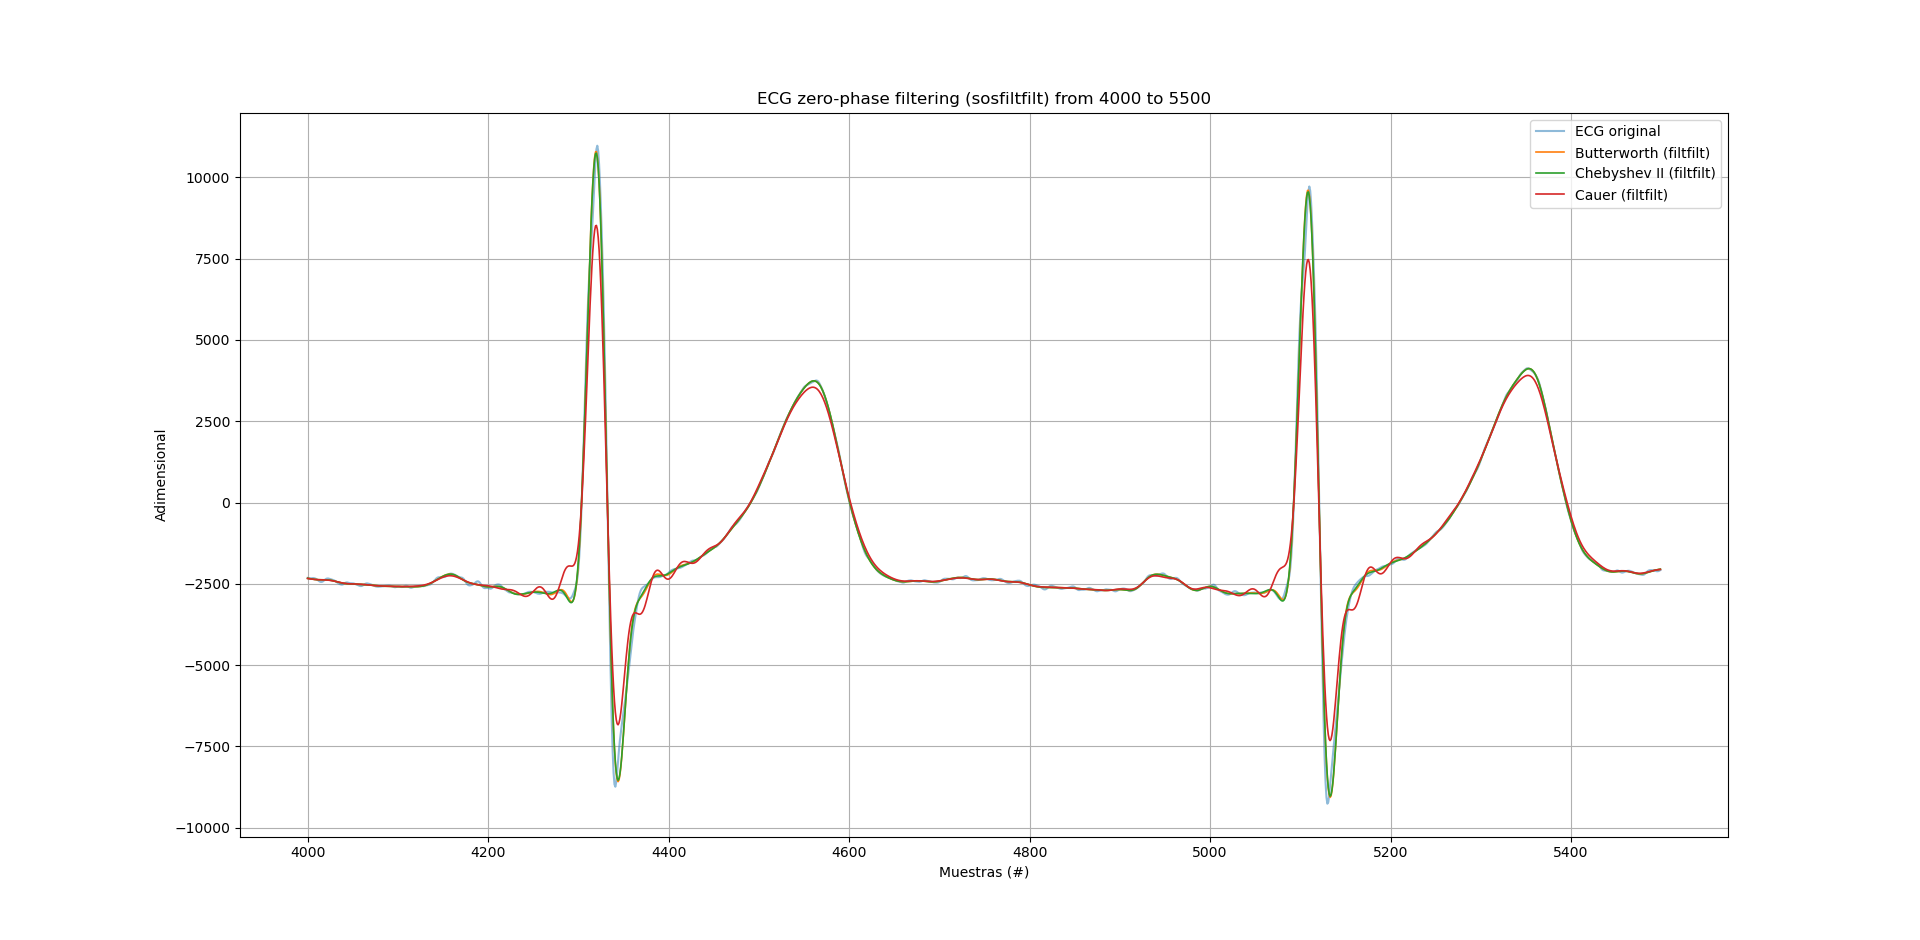

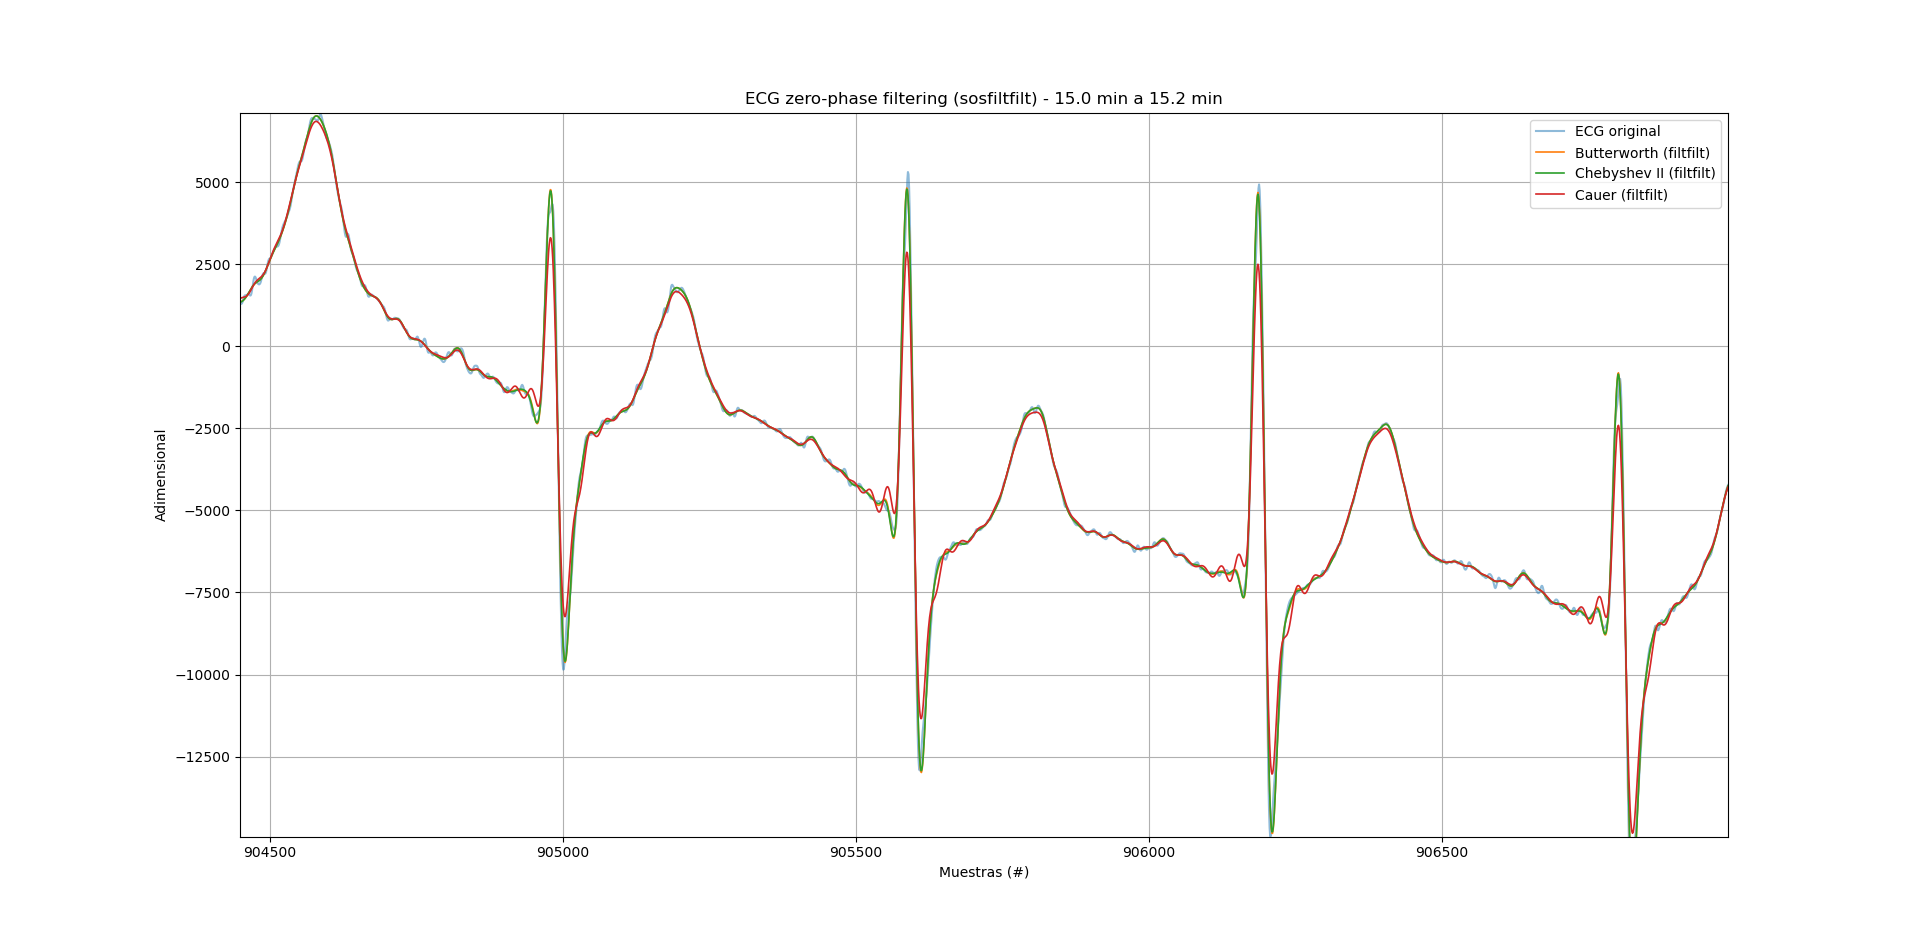

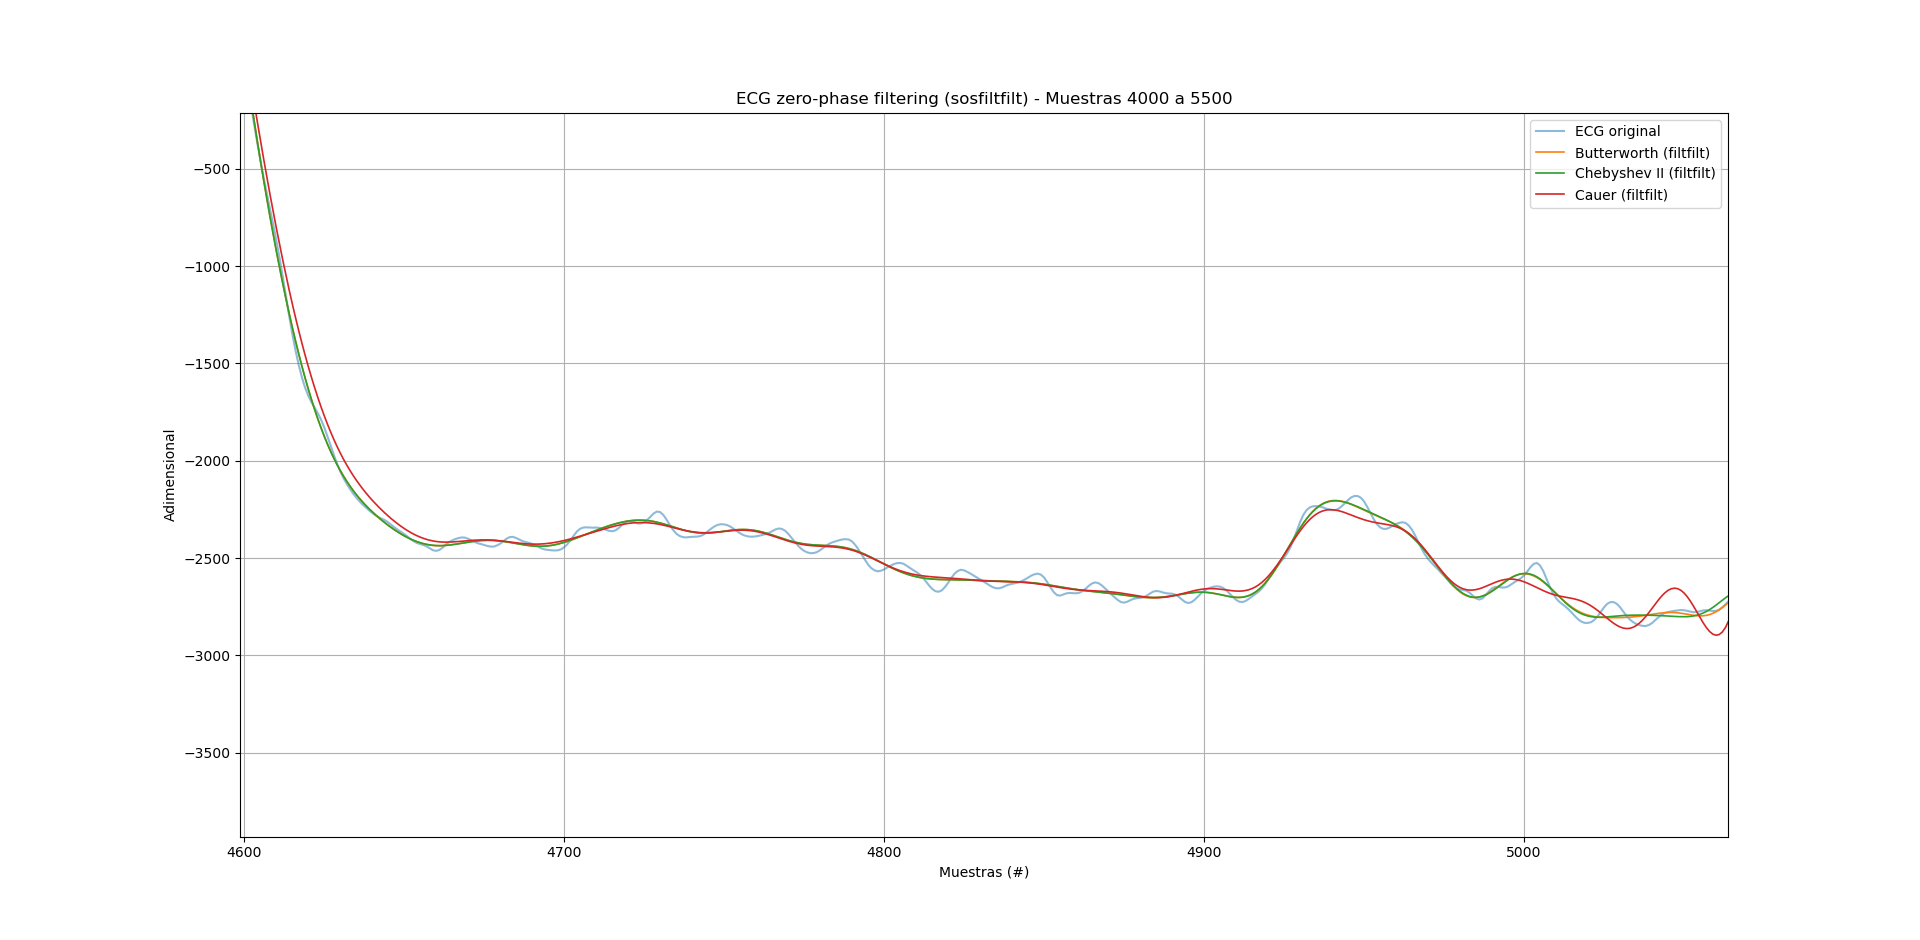

Tras la aplicación del filtrado bidireccional, se observan los siguientes fenómenos clave en la señal de ECG:

1. **Alineación temporal perfecta (Fase cero):**
   * Todas las señales filtradas se encuentran **estrictamente alineadas en el tiempo** con los picos de la señal original, confirmando la cancelación efectiva del retardo de grupo.

2. **Reducción del ruido de alta frecuencia:**
   * En los segmentos de la línea base (visibles con mayor detalle entre las muestras 4700 y 5000), los tres filtros eliminan el "grosor" o rizado de alta frecuencia del ECG original, entregando un trazo limpio.

3. **Distorsión morfológica y *ringing* en el Filtro de Cauer:**
   * **Atenuación de amplitudes extremas (Complejo QRS):** El filtro de Cauer sufre una clara atenuación en las deflexiones rápidas (disminución de la amplitud del pico R y de la profundidad del punto Q/S). Esto sucede porque el filtrado bidireccional duplica el impacto de la respuesta transitoria del filtro, restando energía peak a componentes de cambio rápido.
   * **Ondulaciones residuales (*Ringing*):** Se aprecian pequeñas oscilaciones o rebrotes espurios inmediatamente antes y después de cada complejo QRS. Esto es consecuencia directa del bajo amortiguamiento requerido para su pendiente de caída abrupta.

4. **Desempeño de Butterworth y Chebyshev II:**
   * Tanto Butterworth como Chebyshev II logran **reproducir fielmente la amplitud y la forma del complejo QRS** y de la onda T, eliminando el ruido de alta frecuencia sin introducir artefactos oscilatorios en la línea base.


## 2.2 Filtros FIR

In [24]:
### FUNCION PARA GRAFICAR LA RESPUESTA EN FRECUENCIA.
def calc_resp_fir(b, leg_str, fig_n_axes):
  # Respuesta en frecuencia (a = 1 para FIR)
  f, h = signal.freqz(b, 1, worN=8192, fs=fs_ecg)

  # Módulo en dB
  modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))

  # Fase
  fase_rad = np.unwrap(np.angle(h))

  # Retardo de grupo
  omega = 2 * np.pi * f
  retardo_s = -np.gradient(fase_rad, omega)

  # Evitar graficar retardos en la banda de rechazo profundo
  umbral_db = -80
  valido = modulo_db > umbral_db
  retardo_s_plot = np.where(valido, retardo_s, np.nan)

  (fig, (ax_mod, ax_fase)) = fig_n_axes

  # Módulo
  ax_mod.plot(f, modulo_db, linewidth=1.5, label=leg_str)
  ax_mod.set_ylim(y_min, y_max)
  ax_mod.set_ylabel("Módulo (dB)")
  ax_mod.set_title("Respuesta en frecuencia y plantilla (Filtros FIR)")
  ax_mod.grid(True)

  # Fase
  ax_fase.plot(f, fase_rad, label=leg_str, linewidth=1.2)
  ax_fase.axvline(wp, color="gray", linestyle=":")
  ax_fase.axvline(ws, color="gray", linestyle=":")
  ax_fase.set_xlabel("Frecuencia (Hz)")
  ax_fase.set_ylabel("Fase (rad)")
  ax_fase.grid(True)

  # Retardo de grupo
  plt.figure(2, figsize=(10, 4))
  plt.plot(f, retardo_s_plot, label=leg_str)
  plt.axvline(wp, color="orange", linestyle="--", label=f"wp = {wp} Hz")
  plt.axvline(ws, color="red", linestyle="--", label=f"ws = {ws} Hz")
  plt.xlabel("Frecuencia (Hz)")
  plt.ylabel("Retardo de grupo (s)")
  plt.title("Retardo de grupo de los filtros FIR")
  plt.grid(True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_16376\3674858543.py:39: UserWarning: Ignoring specified arguments in this call because figure with num: 2 already exists
  plt.figure(2, figsize=(10, 4))


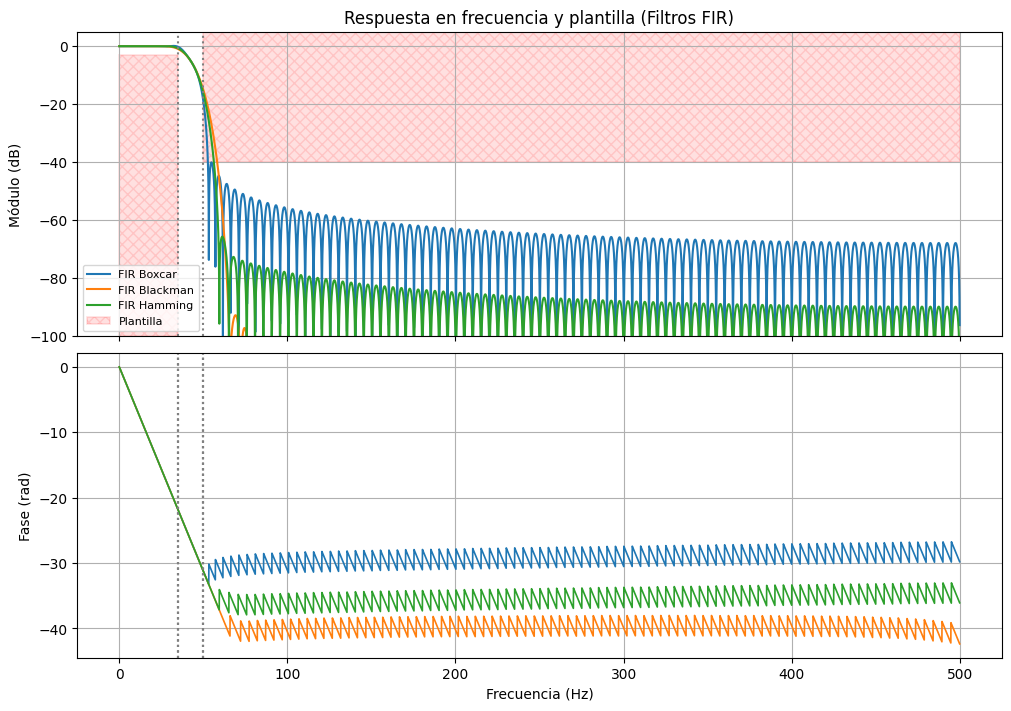

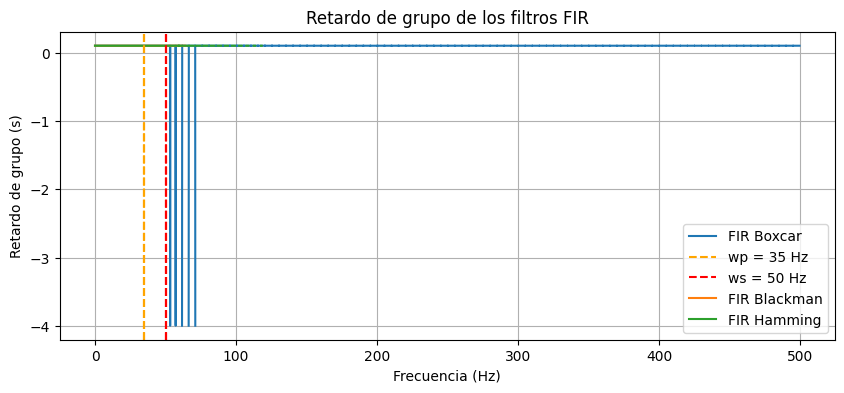

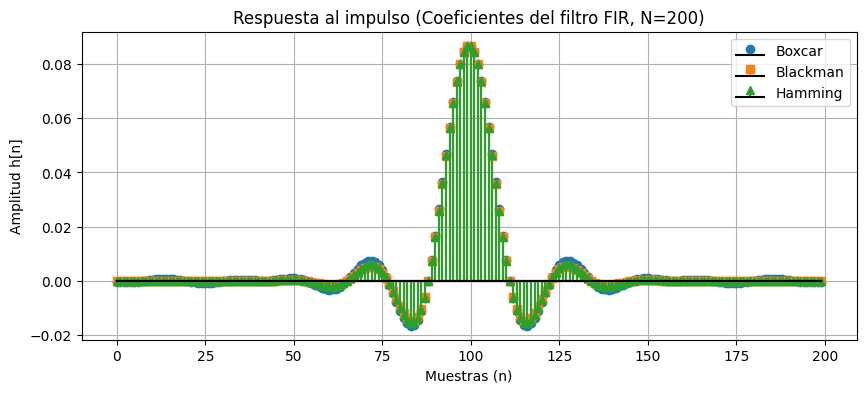

In [25]:
#%% ============================================================
# 1. GRAFICAR RESPUESTAS EN FRECUENCIA (MÓDULO, FASE Y RETARDO)
# ==============================================================

# plt.close("all")

fig_n_axes = plt.subplots(
    2, 1, sharex=True, num=1, figsize=(10, 7), constrained_layout=True
)


taps_win=200
delta_w =2
b_win_boxcar = signal.firwin2( taps_win, [0.0, wp, ws+delta_w, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], window='boxcar', fs = fs_ecg)
b_win_blackman = signal.firwin2( taps_win, [0.0, wp, ws+delta_w, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], window='blackman', fs = fs_ecg)
b_win_hamming = signal.firwin2( taps_win, [0.0, wp, ws+delta_w, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], window='hamming', fs = fs_ecg)


# Graficar cada ventana FIR
calc_resp_fir(b_win_boxcar, "FIR Boxcar", fig_n_axes)
calc_resp_fir(b_win_blackman, "FIR Blackman", fig_n_axes)
calc_resp_fir(b_win_hamming, "FIR Hamming", fig_n_axes)


#%% ============================================================
# 2. SUPERPONER PLANTILLA DEL FILTRO
# ============================================================

(fig, (ax_mod, ax_fase)) = fig_n_axes

# Banda pasante
rect_pasante = Rectangle(
    (0, y_min),
    wp,
    -ripple - y_min,
    facecolor="red",
    alpha=0.12,
    edgecolor="red",
    hatch="xxx",
    linewidth=1.2,
    label="Plantilla",
)
ax_mod.add_patch(rect_pasante)

# Banda de rechazo
rect_rechazo = Rectangle(
    (ws, -att),
    fs_ecg / 2 - ws,
    y_max + att,
    facecolor="red",
    alpha=0.12,
    edgecolor="red",
    hatch="xxx",
    linewidth=1.2,
)
ax_mod.add_patch(rect_rechazo)

# Límites de frecuencia y leyendas
ax_mod.axvline(wp, color="gray", linestyle=":")
ax_mod.axvline(ws, color="gray", linestyle=":")

ax_mod.legend(loc="lower left", fontsize=8)

# Leyenda de retardo de grupo (evitar duplicados de wp/ws)
plt.figure(2)
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())


#%% ============================================================
# 3. GRAFICAR RESPUESTA AL IMPULSO (COEFICIENTES b)
# ============================================================

plt.figure(3, figsize=(10, 4))

n_taps = np.arange(taps_win)

plt.stem(
    n_taps,
    b_win_boxcar,
    linefmt="C0-",
    markerfmt="C0o",
    basefmt="k-",
    label="Boxcar",
)
plt.stem(
    n_taps,
    b_win_blackman,
    linefmt="C1-",
    markerfmt="C1s",
    basefmt="k-",
    label="Blackman",
)
plt.stem(
    n_taps,
    b_win_hamming,
    linefmt="C2-",
    markerfmt="C2^",
    basefmt="k-",
    label="Hamming",
)

plt.title(f"Respuesta al impulso (Coeficientes del filtro FIR, N={taps_win})")
plt.xlabel("Muestras (n)")
plt.ylabel("Amplitud h[n]")
plt.grid(True)
plt.legend()

plt.show()


IR VARIANDO NUMERO DE TAPS Y WP Y WS HASTA QUE CUMPLA CON LA PLANTILLA DE FILTRO , PROBAR VALORES

In [26]:
FILTRADO DE LA SEÑAL

SyntaxError: invalid syntax (3958733966.py, line 1)

In [ ]:
#%% ============================================================
# FILTRADO DE LA SEÑAL ECG CON FILTROS FIR
# ============================================================


ECG_f_boxcar = signal.lfilter(b_win_boxcar, 1, ecg_one_lead)
ECG_f_blackman = signal.lfilter(b_win_blackman, 1, ecg_one_lead)
ECG_f_hamming = signal.lfilter(b_win_hamming, 1, ecg_one_lead)

In [ ]:
#%% ============================================================
# REGIONES DE INTERÉS CON RUIDO (FILTROS FIR)
# ============================================================

cant_muestras = ecg_one_lead.shape[0]

regs_interes = (
    [4000, 5500],  # muestras
    [10e3, 11e3],  # muestras
)

for ii in regs_interes:

  # Intervalo limitado de 0 a cant_muestras
  inicio = int(max(0, ii[0]))
  fin = int(min(cant_muestras, ii[1]))

  zoom_region = np.arange(inicio, fin)

  plt.figure(figsize=(12, 5))

  # Señal Original
  plt.plot(
      zoom_region,
      ecg_one_lead[inicio:fin],
      label='ECG original',
      linewidth=1.5,
      alpha=0.6,
  )

  # Graficado directo de las señales filtradas (con su retardo natural)
  plt.plot(
      zoom_region,
      ECG_f_boxcar[inicio:fin],
      label='FIR Boxcar',
      linewidth=1.2,
  )

  plt.plot(
      zoom_region,
      ECG_f_blackman[inicio:fin],
      label='FIR Blackman',
      linewidth=1.2,
  )

  plt.plot(
      zoom_region,
      ECG_f_hamming[inicio:fin],
      label='FIR Hamming',
      linewidth=1.2,
  )

  plt.title(
      'ECG FIR filtering example from ' + str(inicio) + ' to ' + str(fin)
  )

  plt.ylabel('Adimensional')
  plt.xlabel('Muestras (#)')

  axes_hdl = plt.gca()
  axes_hdl.legend()
  axes_hdl.set_yticks(())

  plt.show()

In [ ]:
FILTROS CON BUTT VENTANEO , FALTA HACER CON CUADRADOS Y PARK.